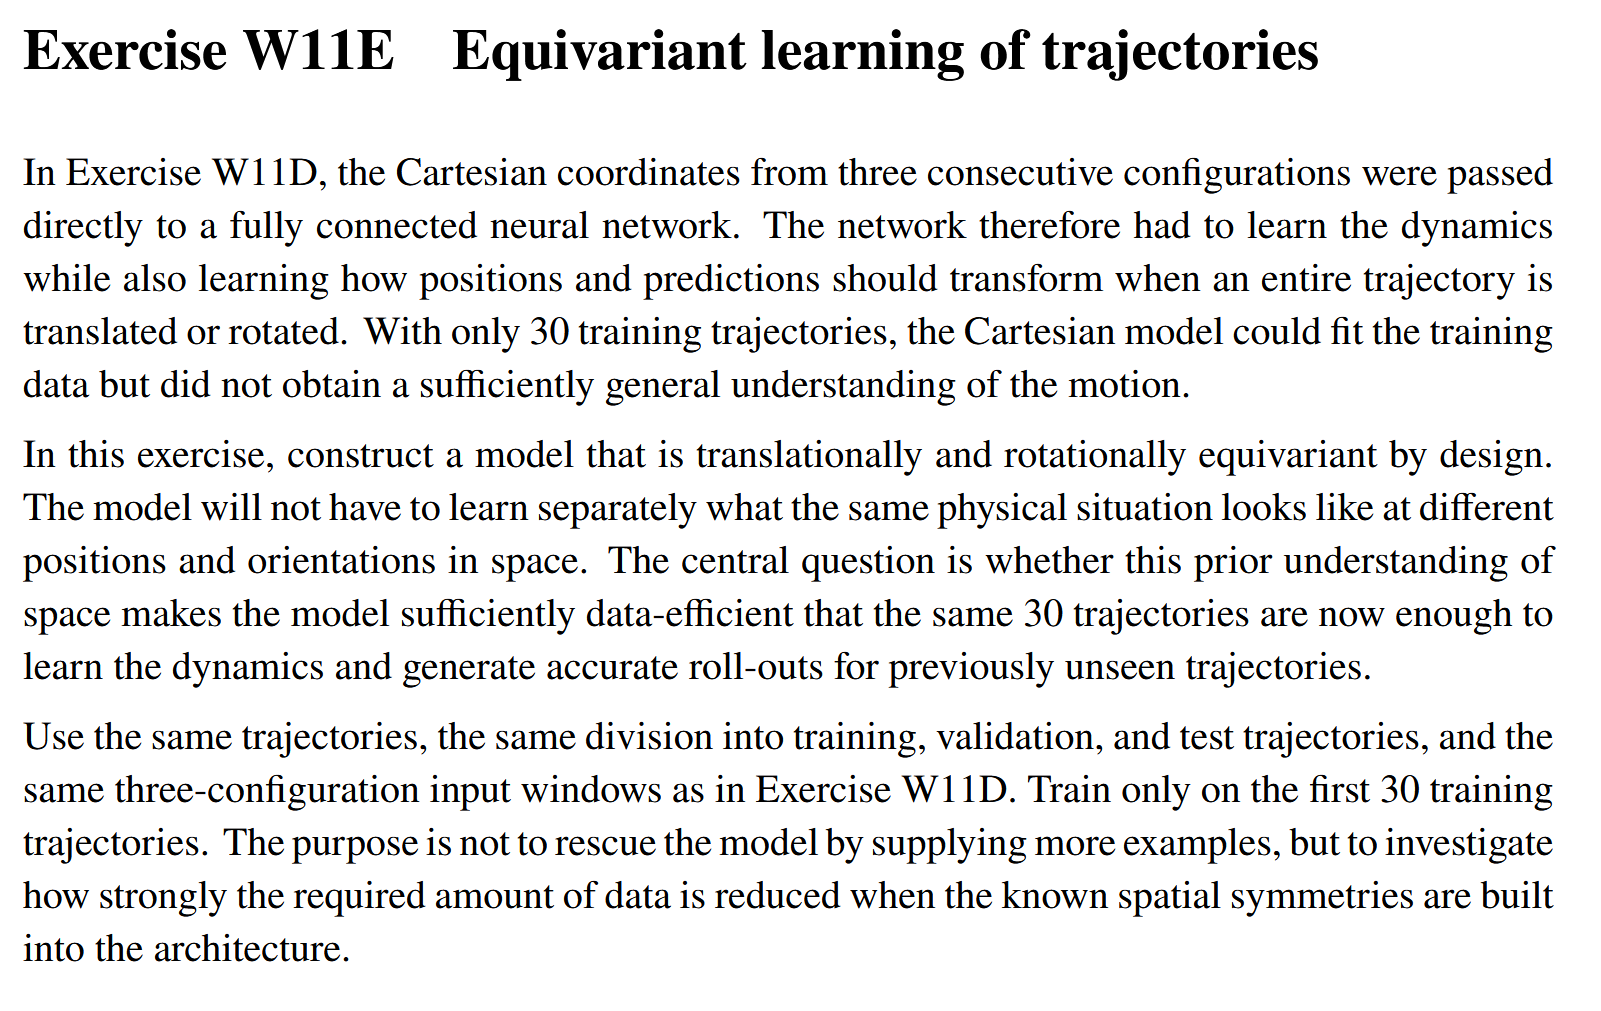
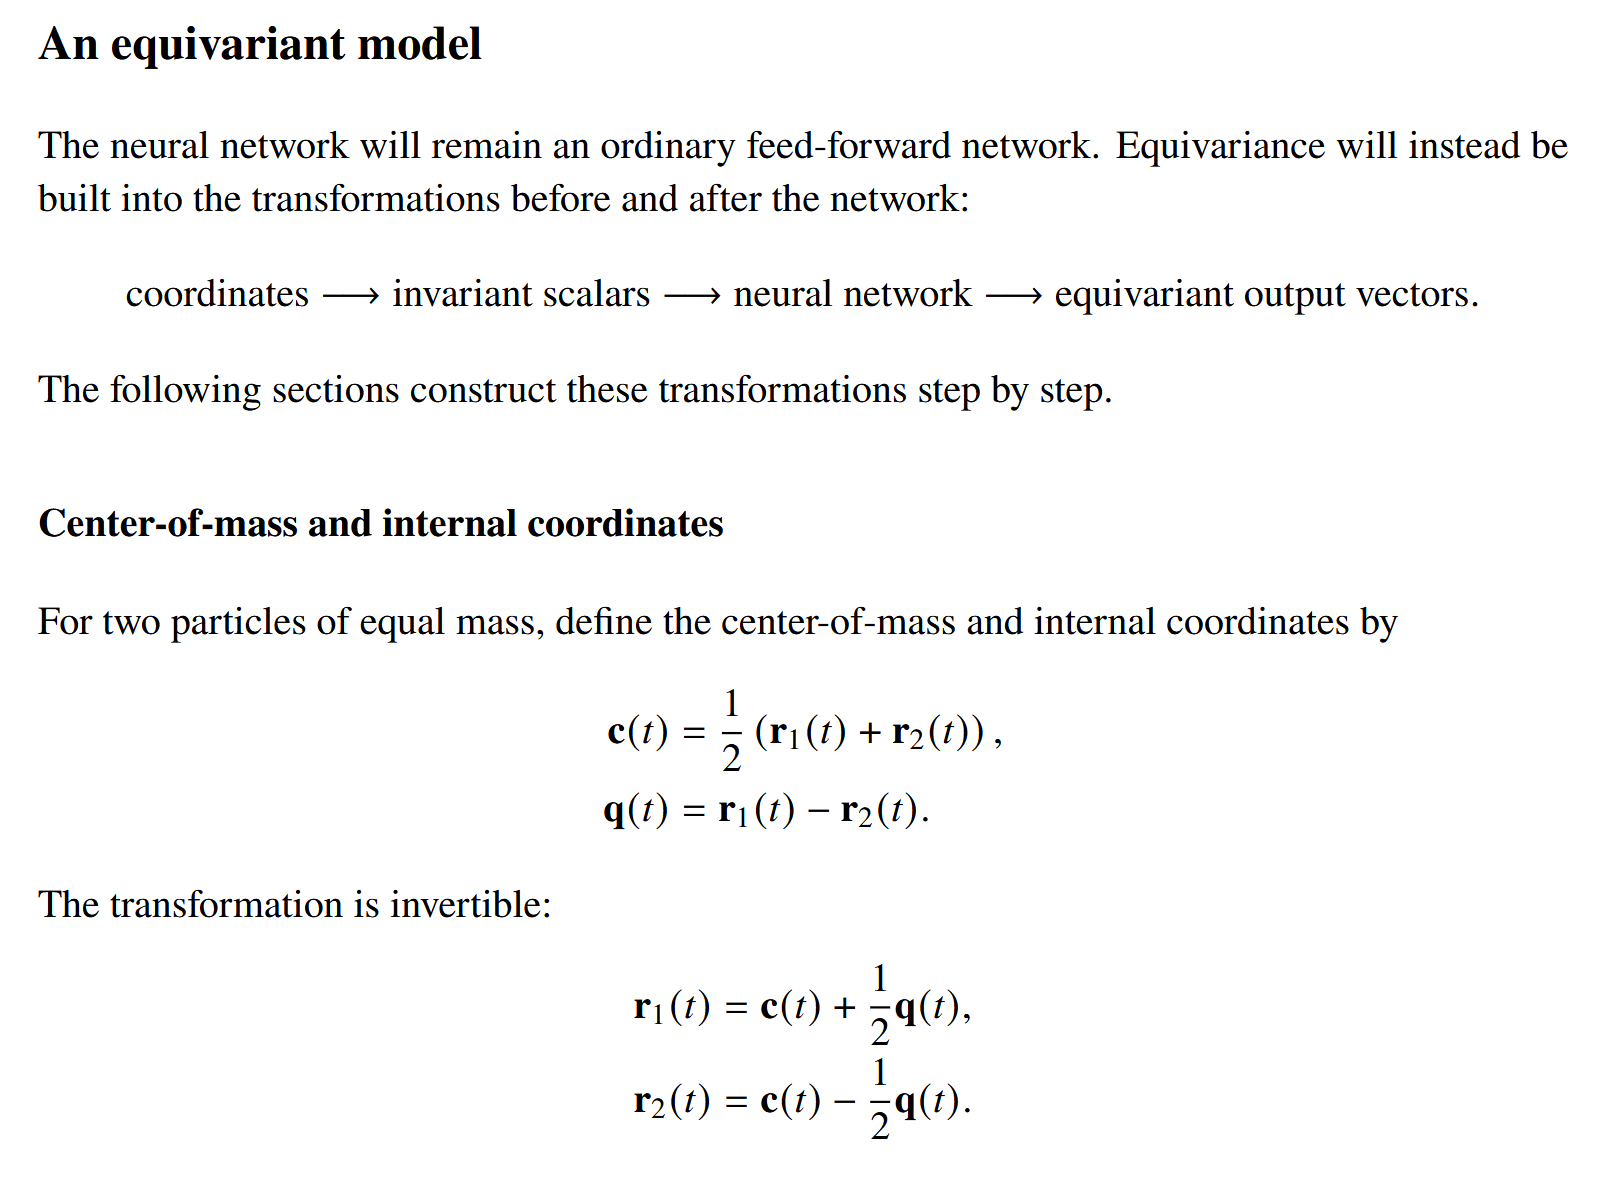
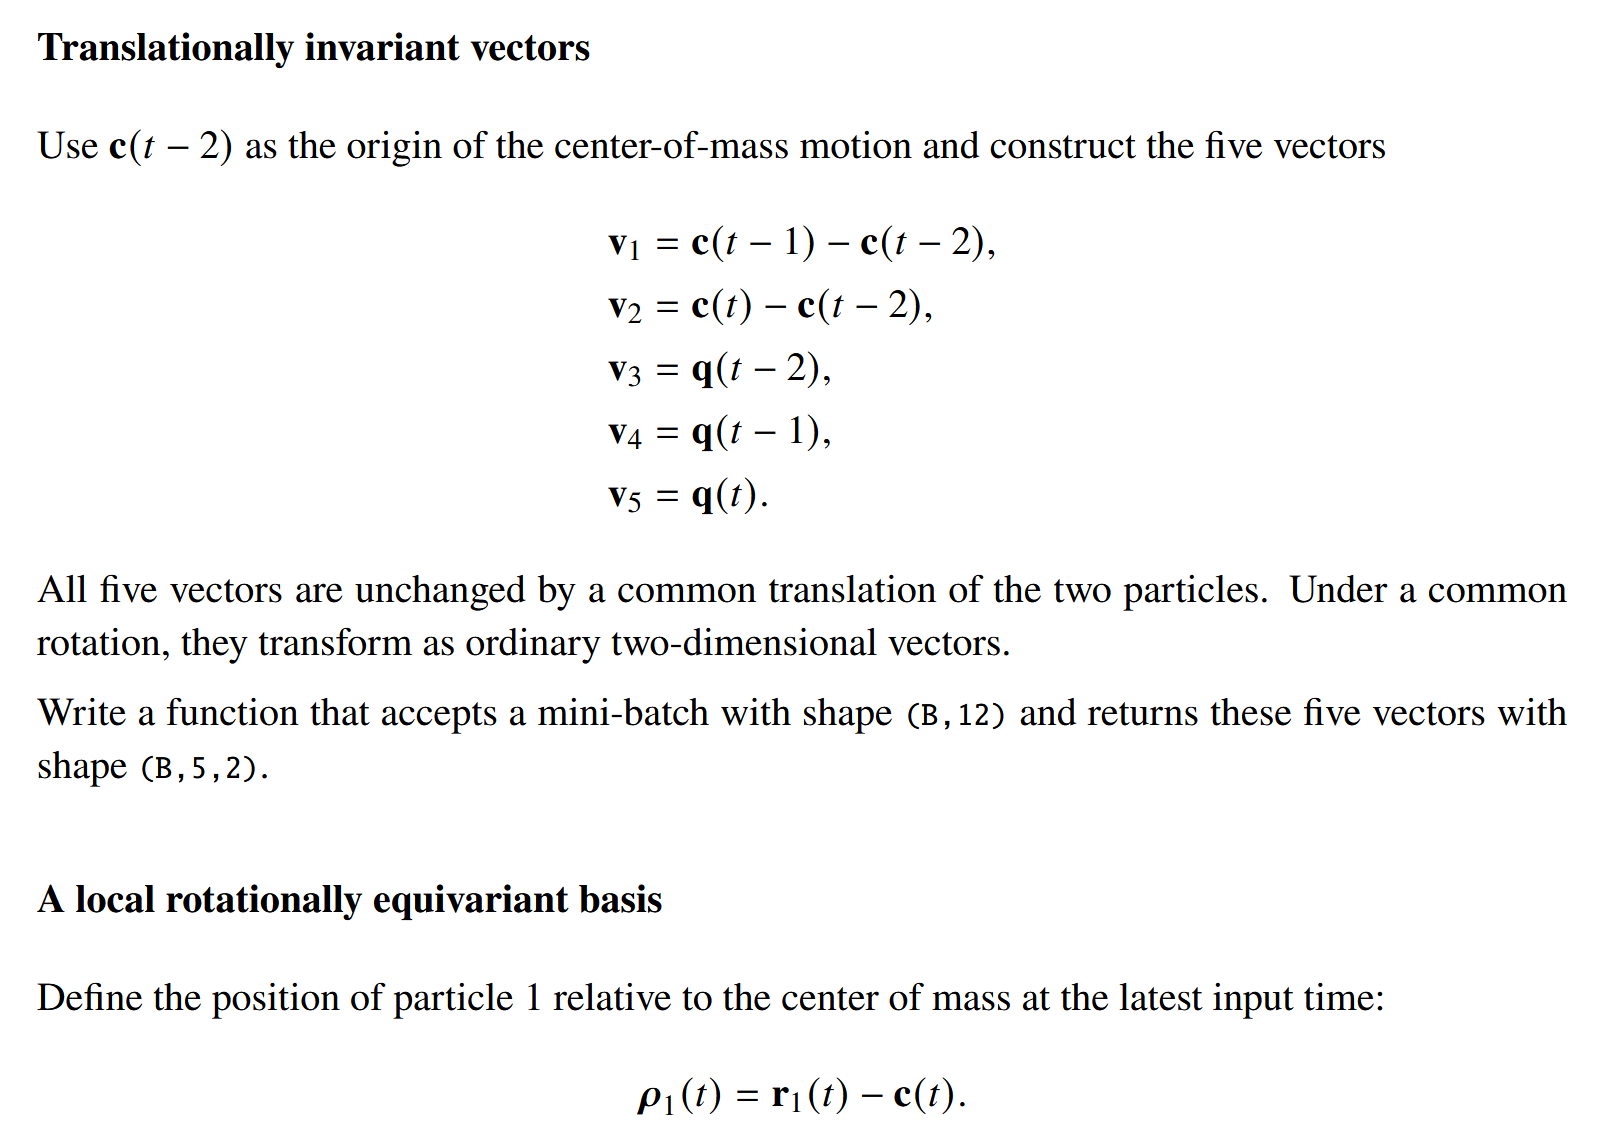
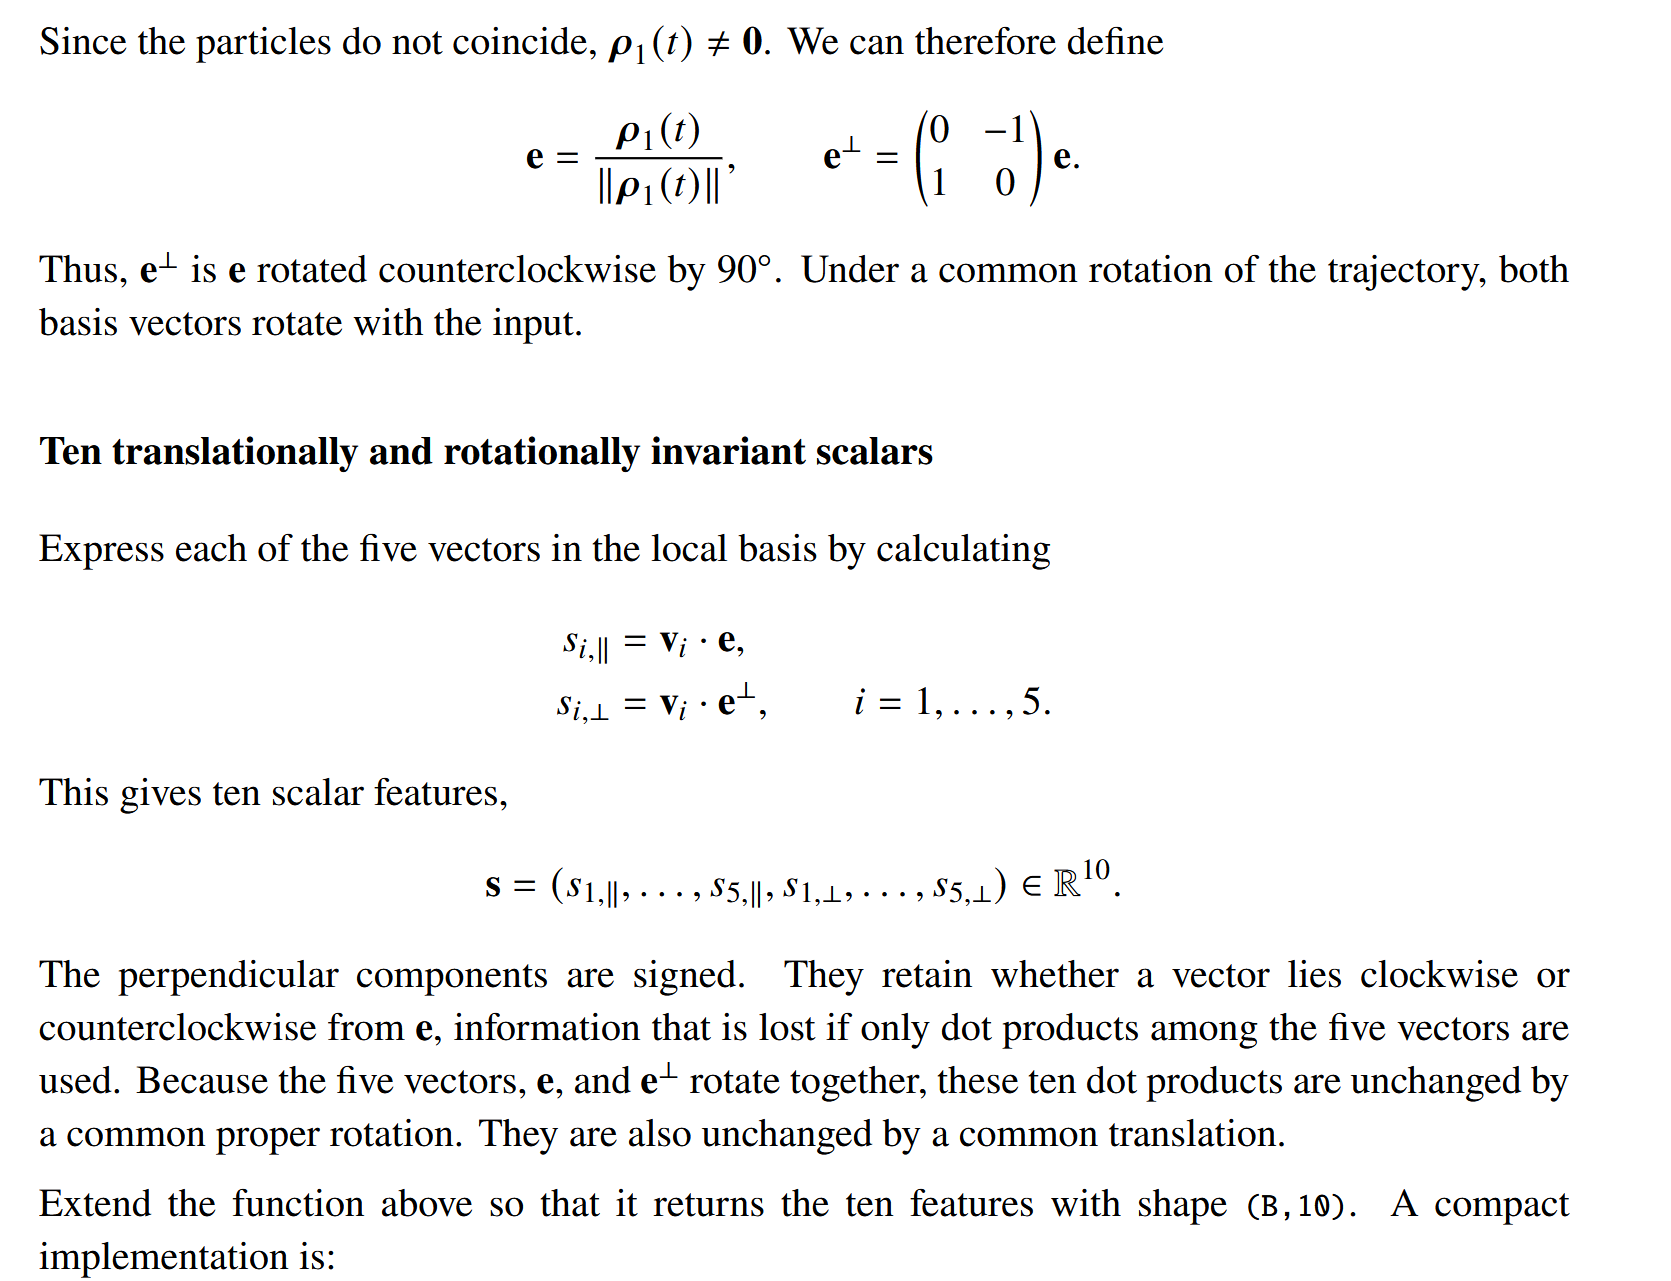

In [34]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
from models import *

def invariant_features(x):
    r = x.view(-1, 3, 2, 2)
    
    c = 0.5 * (r[:, :, 0, :] + r[:, :, 1, :])
    q = r[:, :, 0, :] - r[:, :, 1, :]
    
    v1 = c[:, 1, :] - c[:, 0, :]
    v2 = c[:, 2, :] - c[:, 0, :]
    v3 = q[:, 0, :]
    v4 = q[:, 1, :]
    v5 = q[:, 2, :]
    
    vectors = torch.stack((v1, v2, v3, v4, v5), dim=1)
    
    rho1 = r[:, 2, 0, :] - c[:, 2, :]
    e = rho1 / torch.linalg.vector_norm(rho1, dim=1, keepdim=True)
    e_perp = torch.stack((-e[:, 1], e[:, 0]), dim=1)
    
    parallel = torch.sum(vectors * e[:, None, :], dim=2)
    perpendicular = torch.sum(vectors * e_perp[:, None, :], dim=2)
    
    invariants = torch.cat((parallel, perpendicular), dim=1)
    
    return invariants

loaded = np.load("trajectories.npz")
data = loaded["trajectories"].astype(np.float32)

train_traj_30 = data[:30]
train_data = TrajectoryDataset(train_traj_30)

x = train_data[0][0] 

print(invariant_features(x.reshape(1, -1))[0])

shift = torch.tensor([2.0, 1.0], dtype=x.dtype)
x_shifted = x.view(3, 2, 2) + shift
print(invariant_features(x_shifted.reshape(1, -1))[0])

theta = torch.tensor(torch.pi / 6)
R = torch.stack([
    torch.stack([torch.cos(theta), -torch.sin(theta)]),
    torch.stack([torch.sin(theta), torch.cos(theta)])
])

positions = x.view(-1, 2).T
rotated_positions = (R @ positions).T.view(1, 3, 2, 2)
print(invariant_features(rotated_positions.reshape(1, -1))[0])


tensor([0.0624, 0.1248, 1.0600, 1.3474, 1.5257, 0.1449, 0.2899, 0.8971, 0.4678,
        0.0000])
tensor([ 6.2413e-02,  1.2483e-01,  1.0600e+00,  1.3474e+00,  1.5257e+00,
         1.4494e-01,  2.8989e-01,  8.9715e-01,  4.6782e-01, -4.6566e-10])
tensor([6.2413e-02, 1.2483e-01, 1.0600e+00, 1.3474e+00, 1.5257e+00, 1.4494e-01,
        2.8989e-01, 8.9715e-01, 4.6782e-01, 5.9605e-08])


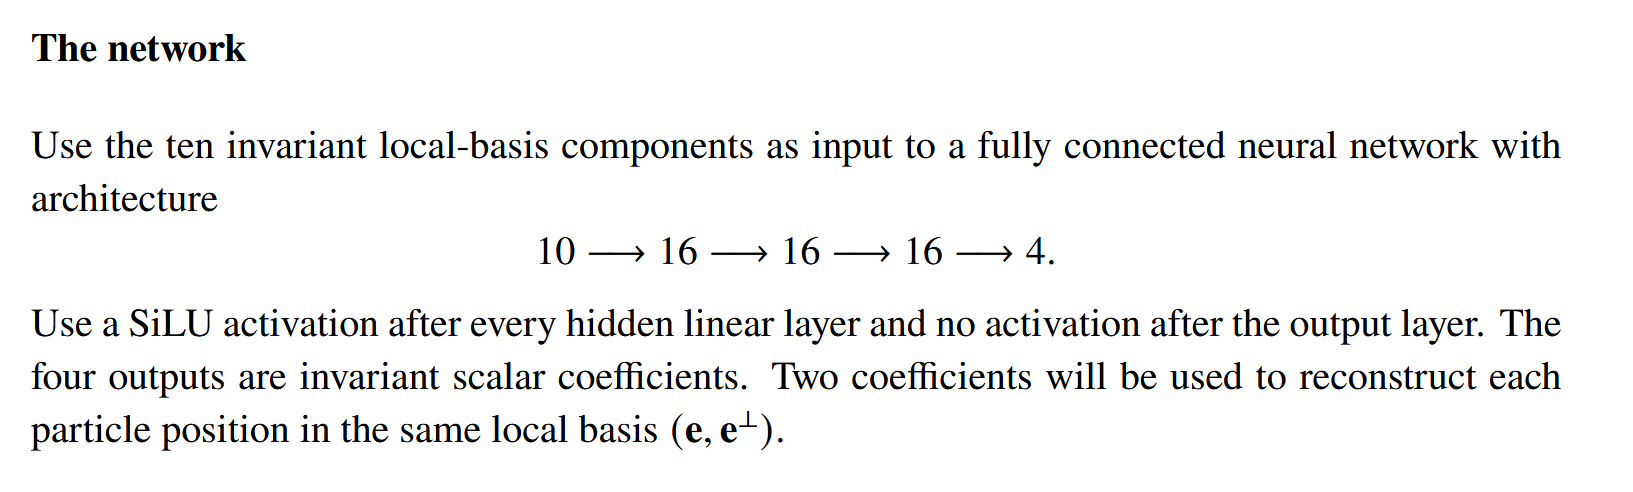
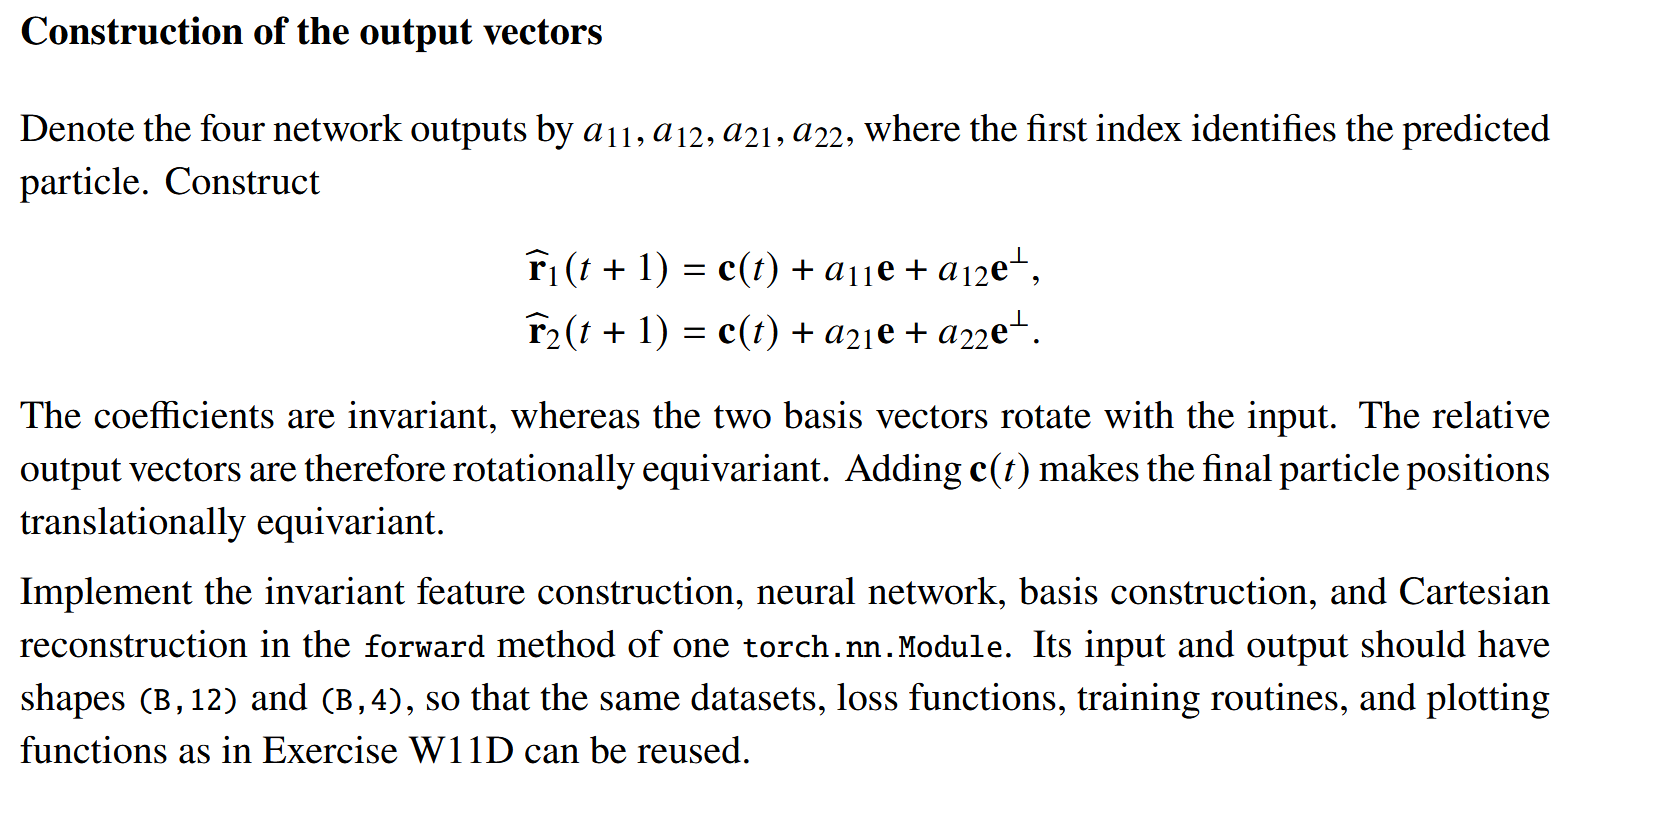

In [35]:
class EquivariantModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(10, 16),
            nn.SiLU(),
            nn.Linear(16, 16),
            nn.SiLU(),
            nn.Linear(16, 16),
            nn.SiLU(),
            nn.Linear(16, 4)
        )

    def forward(self, x):
        r = x.view(-1, 3, 2, 2)
        
        c = 0.5 * (r[:, :, 0, :] + r[:, :, 1, :])
        q = r[:, :, 0, :] - r[:, :, 1, :]
        
        v1 = c[:, 1, :] - c[:, 0, :]
        v2 = c[:, 2, :] - c[:, 0, :]
        v3 = q[:, 0, :]
        v4 = q[:, 1, :]
        v5 = q[:, 2, :]
        
        vectors = torch.stack((v1, v2, v3, v4, v5), dim=1)
        
        rho1 = r[:, 2, 0, :] - c[:, 2, :]
        e = rho1 / torch.linalg.vector_norm(rho1, dim=1, keepdim=True)
        e_perp = torch.stack((-e[:, 1], e[:, 0]), dim=1)
        
        parallel = torch.sum(vectors * e[:, None, :], dim=2)
        perpendicular = torch.sum(vectors * e_perp[:, None, :], dim=2)
        
        invariants = torch.cat((parallel, perpendicular), dim=1)
        
        out = self.net(invariants)
        
        a11, a12, a21, a22 = out[:, 0:1], out[:, 1:2], out[:, 2:3], out[:, 3:4]
        
        c_t = c[:, 2, :]
        
        r1_hat = c_t + a11 * e + a12 * e_perp
        r2_hat = c_t + a21 * e + a22 * e_perp
        
        return torch.cat((r1_hat, r2_hat), dim=1)


In [36]:
model = EquivariantModel()
model.eval()

p = x.view(1, 3, 2, 2)
a = torch.tensor([2.0, -1.5])
p_translated = p + a

fp = model(p.view(1, 12))
fp_translated = model(p_translated.view(1, 12))

print("Translation Equivariance Test:")
print("f(p) + a:      ", fp.view(2, 2) + a)
print("f(p + a):      ", fp_translated.view(2, 2))
print("Are they equal?", torch.allclose(fp.view(2, 2) + a, fp_translated.view(2, 2), atol=1e-5))

Rp = (R @ p.reshape(-1, 2).T).T.reshape(1, 3, 2, 2)

fRp = model(Rp.reshape(1, 12))
Rfp = (R @ fp.reshape(2, 2).T).T.reshape(1, 4)

print("\nRotation Equivariance Test:")
print("f(Rp):         ", fRp)
print("R f(p):        ", Rfp)
print("Are they equal?", torch.allclose(fRp, Rfp, atol=1e-5))

Translation Equivariance Test:
f(p) + a:       tensor([[ 0.9075, -1.0767],
        [ 0.7798, -1.0362]], grad_fn=<AddBackward0>)
f(p + a):       tensor([[ 0.9075, -1.0767],
        [ 0.7798, -1.0362]], grad_fn=<ViewBackward0>)
Are they equal? True

Rotation Equivariance Test:
f(Rp):          tensor([[-1.1578, -0.1796, -1.2887, -0.2084]], grad_fn=<CatBackward0>)
R f(p):         tensor([[-1.1578, -0.1796, -1.2887, -0.2084]], grad_fn=<UnsafeViewBackward0>)
Are they equal? True


### Tests of Equivariance

* **Translational Equivariance:** The 10 network inputs depend strictly on relative distance vectors (like $c(t-1) - c(t-2)$ and $r_1(t) - r_2(t)$). Adding a constant translation vector $a$ to all coordinates cancels out mathematically when computing these relative differences, meaning the inputs—and therefore the four scalar coefficients produced by the network—remain entirely unchanged. Because the final output is reconstructed by adding $c(t)$ back to the relative basis components, and $c(t)$ now includes the shift $a$, the entire predicted configuration is perfectly translated by $a$.


* **Rotational Equivariance:** The features are generated by projecting vectors onto a local basis ($e$ and $e^\perp$) that is dynamically defined by the input particles. When the input trajectory is rotated by $R$, the relative vectors rotate, but the basis vectors $e$ and $e^\perp$ also rotate by the exact same amount $R$, leaving the resulting dot products (the scalar inputs to the network) entirely unchanged. The network outputs the same scalar coefficients, which scale the now-rotated basis vectors, guaranteeing the output prediction naturally rotates alongside the input.


* **Independence from Training:** Both of these identities hold exactly for arbitrary network parameters prior to training because the spatial symmetries are strictly enforced by the geometric transformations executed before and after the neural network. The neural network only processes invariant scalars, meaning the model "understands space" geometrically by design, regardless of the random weights initialized in its linear layers.

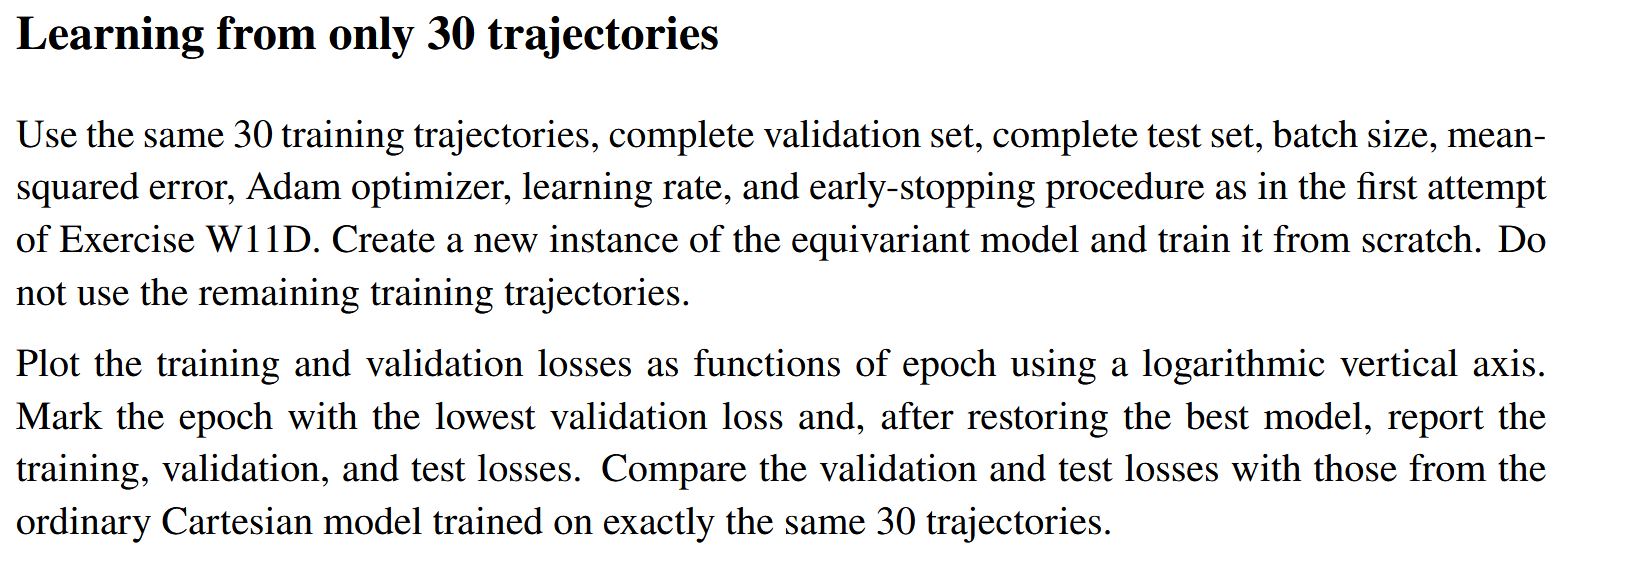

Early stopping triggered at epoch 12639. Restoring best weights.
Final Test Loss: 0.000140


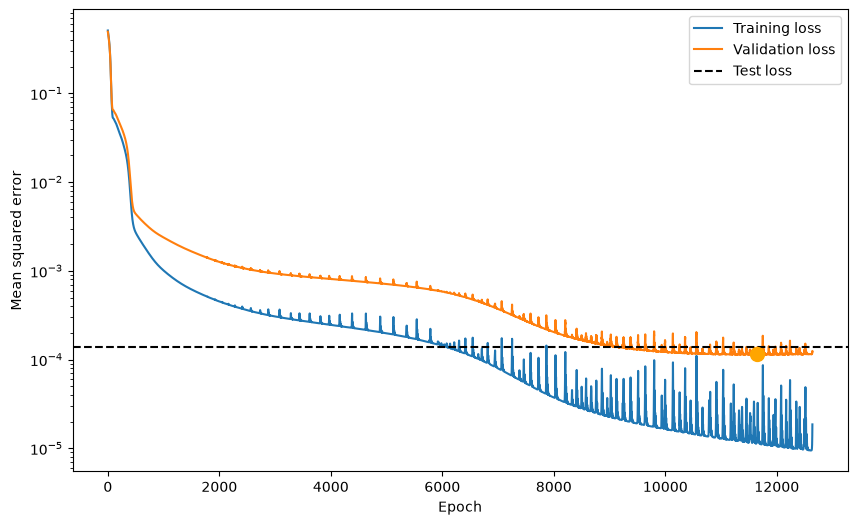

Final Train Loss: 0.000011
Final Validation Loss: 0.000114


In [37]:
import copy

# Extract the exact subsets requested for Exercise W11E
train_traj_30 = data[:30]
val_traj = data[800:900]
test_traj = data[900:1000]

# Instantiate the datasets
train_data = TrajectoryDataset(train_traj_30)
val_data = TrajectoryDataset(val_traj)
test_data = TrajectoryDataset(test_traj)

# Recreate the loaders. Using full-batch sizes prevents the Python loop bottleneck.
train_loader = DataLoader(train_data, batch_size=len(train_data), shuffle=True)
val_loader = DataLoader(val_data, batch_size=len(val_data), shuffle=False)
test_loader = DataLoader(test_data, batch_size=len(test_data), shuffle=False)

trained_model, history = fit_model(
    model=EquivariantModel(),
    train_loader=train_loader,
    criterion=nn.MSELoss(),
    optimizer_class=torch.optim.Adam,
    lr=1e-3,
    val_loader=val_loader,
    test_loader=test_loader,
    epochs=20000, 
    patience=1000
)

plt.figure(figsize=(10, 6))
plt.plot(history['train_loss'], label='Training loss')
plt.plot(history['val_loss'], label='Validation loss')

best_val_loss = min(history['val_loss'])
best_epoch_idx = history['val_loss'].index(best_val_loss)

plt.axhline(y=history['test_loss'], color='k', linestyle='--', label='Test loss')
plt.scatter([best_epoch_idx], [best_val_loss], color='orange', s=100, zorder=5)

plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Mean squared error')
plt.legend()
plt.show()

print(f"Final Train Loss: {history['train_loss'][best_epoch_idx]:.6f}")
print(f"Final Validation Loss: {best_val_loss:.6f}")

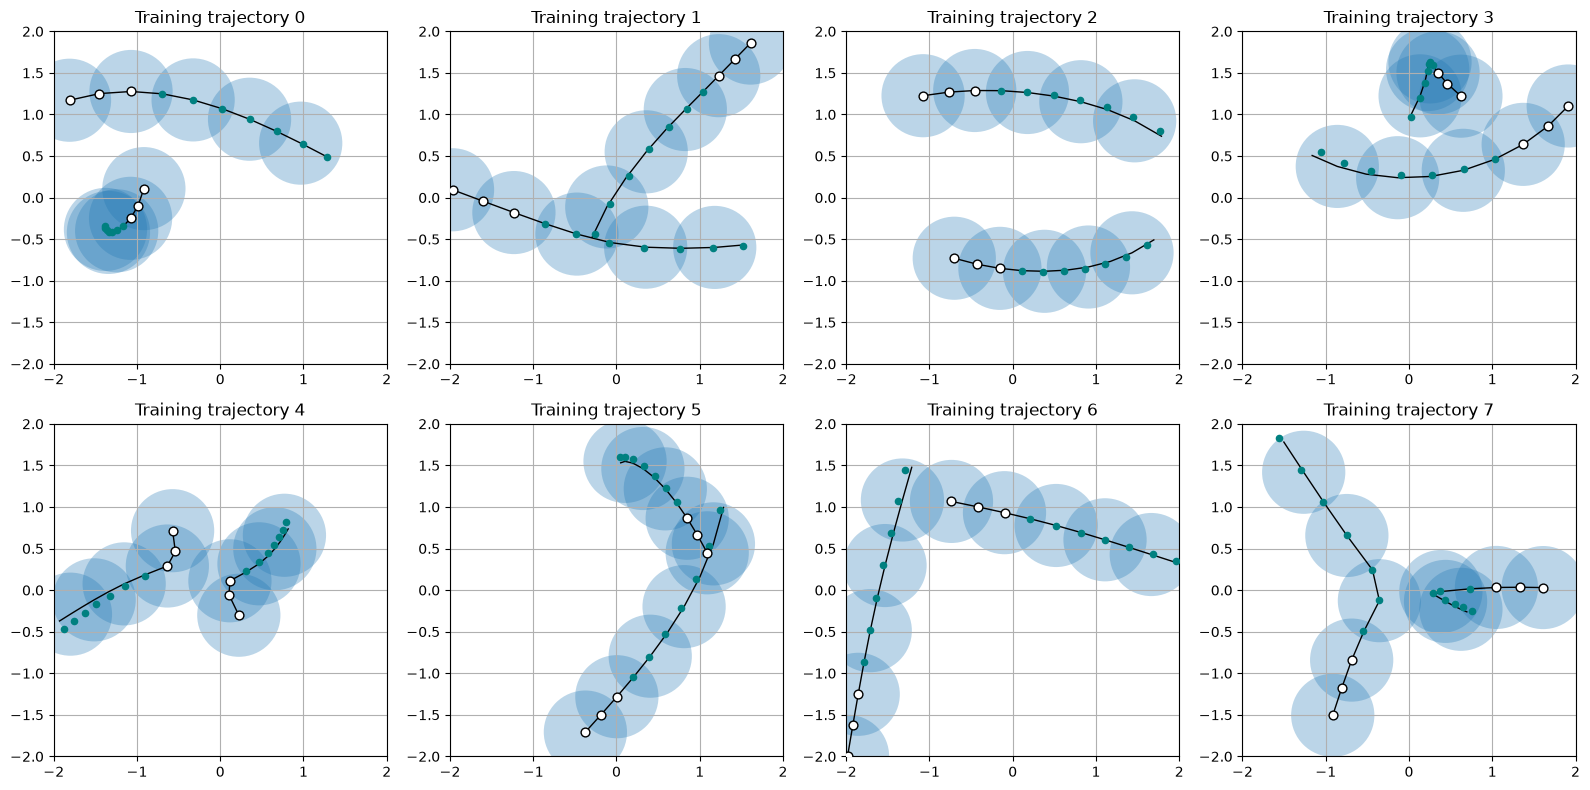

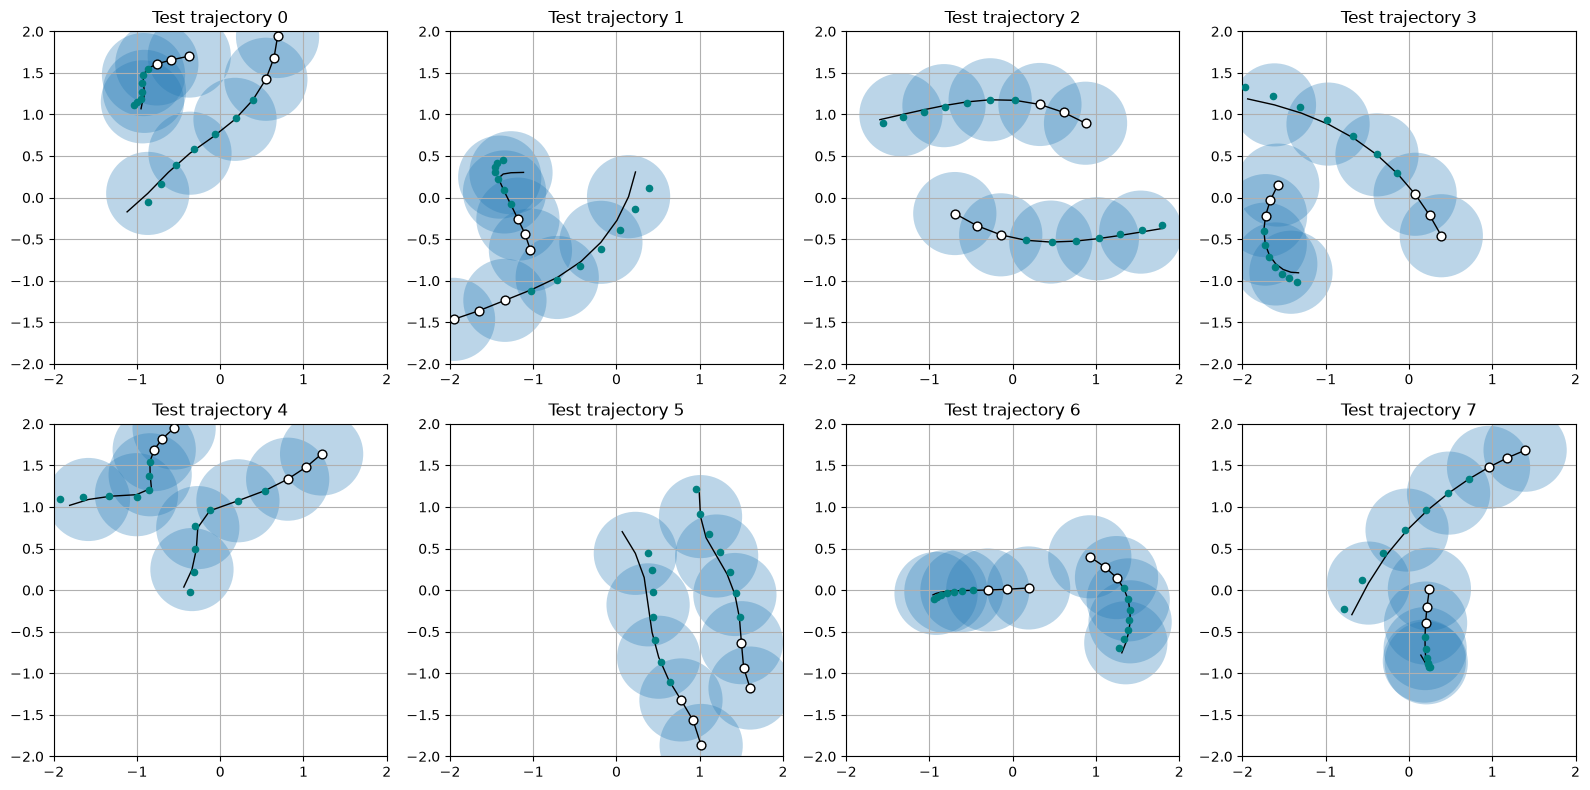

In [38]:
def rollout(model, trajectory):
    """Predict a trajectory from its first three configurations."""
    trajectory = torch.as_tensor(trajectory, dtype=torch.float32)
    window = trajectory[:3]
    prediction = [r for r in window] 

    with torch.no_grad():
        for _ in range(3, len(trajectory)):
            x = window.reshape(1, 12)
            r_new = model(x)[0] 

            prediction.append(r_new)

            window = torch.cat(
                (window[1:], r_new[None, :]),
                dim=0,
            )

    return torch.stack(prediction)

def plot_trajectoriesuivariant(axes, dataset, model, title_prefix, num_plots=8):
    for i in range(num_plots):
        ax = axes[i]
        true_traj = dataset.trajectories[i]
        pred_traj = rollout(model, true_traj)
        
        ax.plot(true_traj[:, 0], true_traj[:, 1], color='black', linewidth=1)
        ax.plot(true_traj[:, 2], true_traj[:, 3], color='black', linewidth=1)
        
        ax.scatter(pred_traj[3:, 0].numpy(), pred_traj[3:, 1].numpy(), color='teal', s=20, zorder=3)
        ax.scatter(pred_traj[3:, 2].numpy(), pred_traj[3:, 3].numpy(), color='teal', s=20, zorder=3)
        
        ax.scatter(true_traj[:3, 0], true_traj[:3, 1], color='white', edgecolor='black', s=40, zorder=4)
        ax.scatter(true_traj[:3, 2], true_traj[:3, 3], color='white', edgecolor='black', s=40, zorder=4)
        
        radius = 0.5
        for t in range(0, len(true_traj), max(1, len(true_traj) // 4)):
            ax.add_patch(plt.Circle((true_traj[t, 0], true_traj[t, 1]), radius, facecolor='tab:blue', alpha=0.3, zorder=1))
            ax.add_patch(plt.Circle((true_traj[t, 2], true_traj[t, 3]), radius, facecolor='tab:blue', alpha=0.3, zorder=1))
            
        ax.set_title(f"{title_prefix} {i}")
        ax.set_xlim(-2, 2)
        ax.set_ylim(-2, 2)
        ax.grid(True)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
plot_trajectoriesuivariant(axes.flatten(), train_data, trained_model, "Training trajectory")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
plot_trajectoriesuivariant(axes.flatten(), test_data, trained_model, "Test trajectory")
plt.tight_layout()
plt.show()

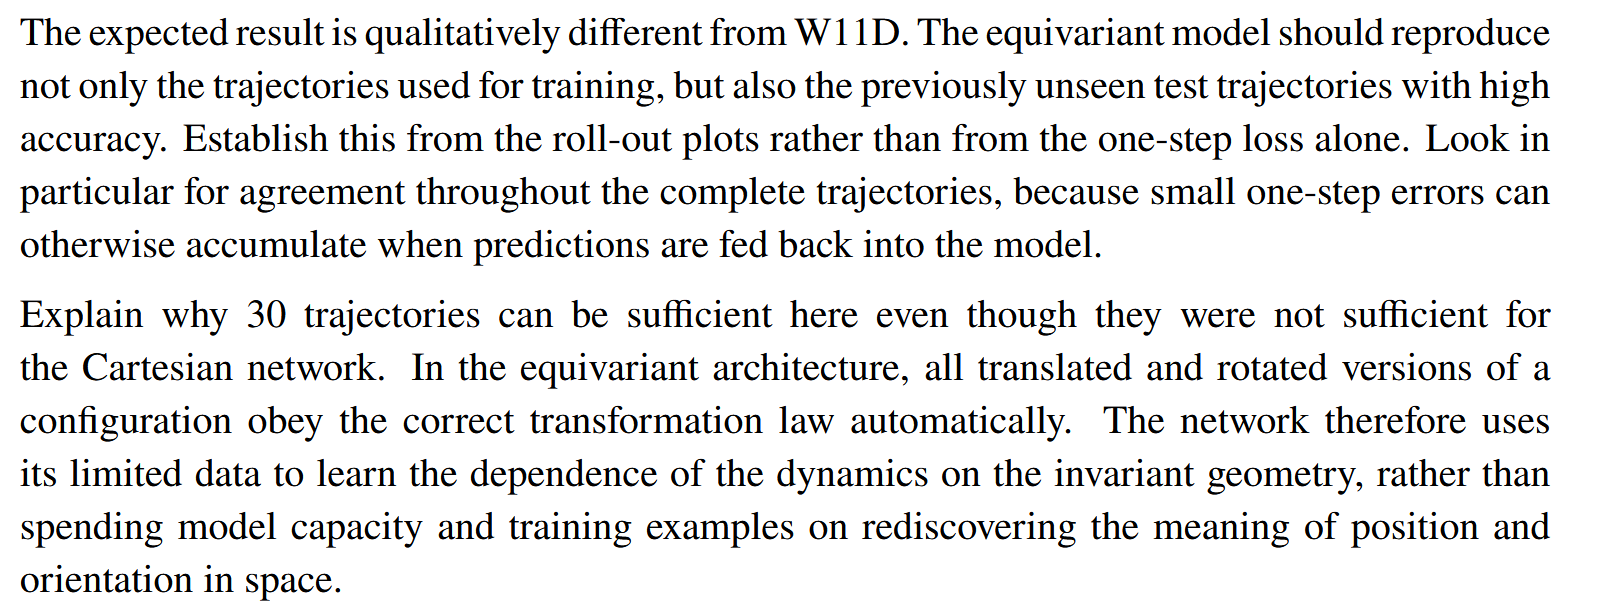

### Comparison, Interpretation, and Symmetry Tests

* **Losses compared to the Cartesian model:** For the standard Cartesian model trained on just 30 trajectories, there is a massive gap between the training loss and the validation/test losses due to overfitting. In the equivariant architecture, the validation and test losses remain exceptionally close to the training loss, reflecting strong generalization.


* **Reliability of roll-outs:** The equivariant model generates highly reliable roll-outs for trajectories that were not included in the training set. Small one-step errors do not accumulate rapidly into massive divergences, unlike the Cartesian model.


* **Data efficiency:** Equivariance allows one training example to represent an entire family of translated and rotated situations because all shifted and rotated variants automatically obey the exact same geometric transformation laws within the model. The network focuses all its capacity strictly on the physical dynamics rather than wasting parameters learning the rules of 2D space.


* **Test-trajectory roll-outs vs. one-step loss:** A successful test-trajectory roll-out is stronger evidence of learning the dynamics than a low one-step training loss because roll-outs feed predictions recursively back into the model; any failure to learn the generalized physics will compound quickly, causing the trajectory to diverge catastrophically. A low training loss alone merely proves the network can memorize data it has already seen.

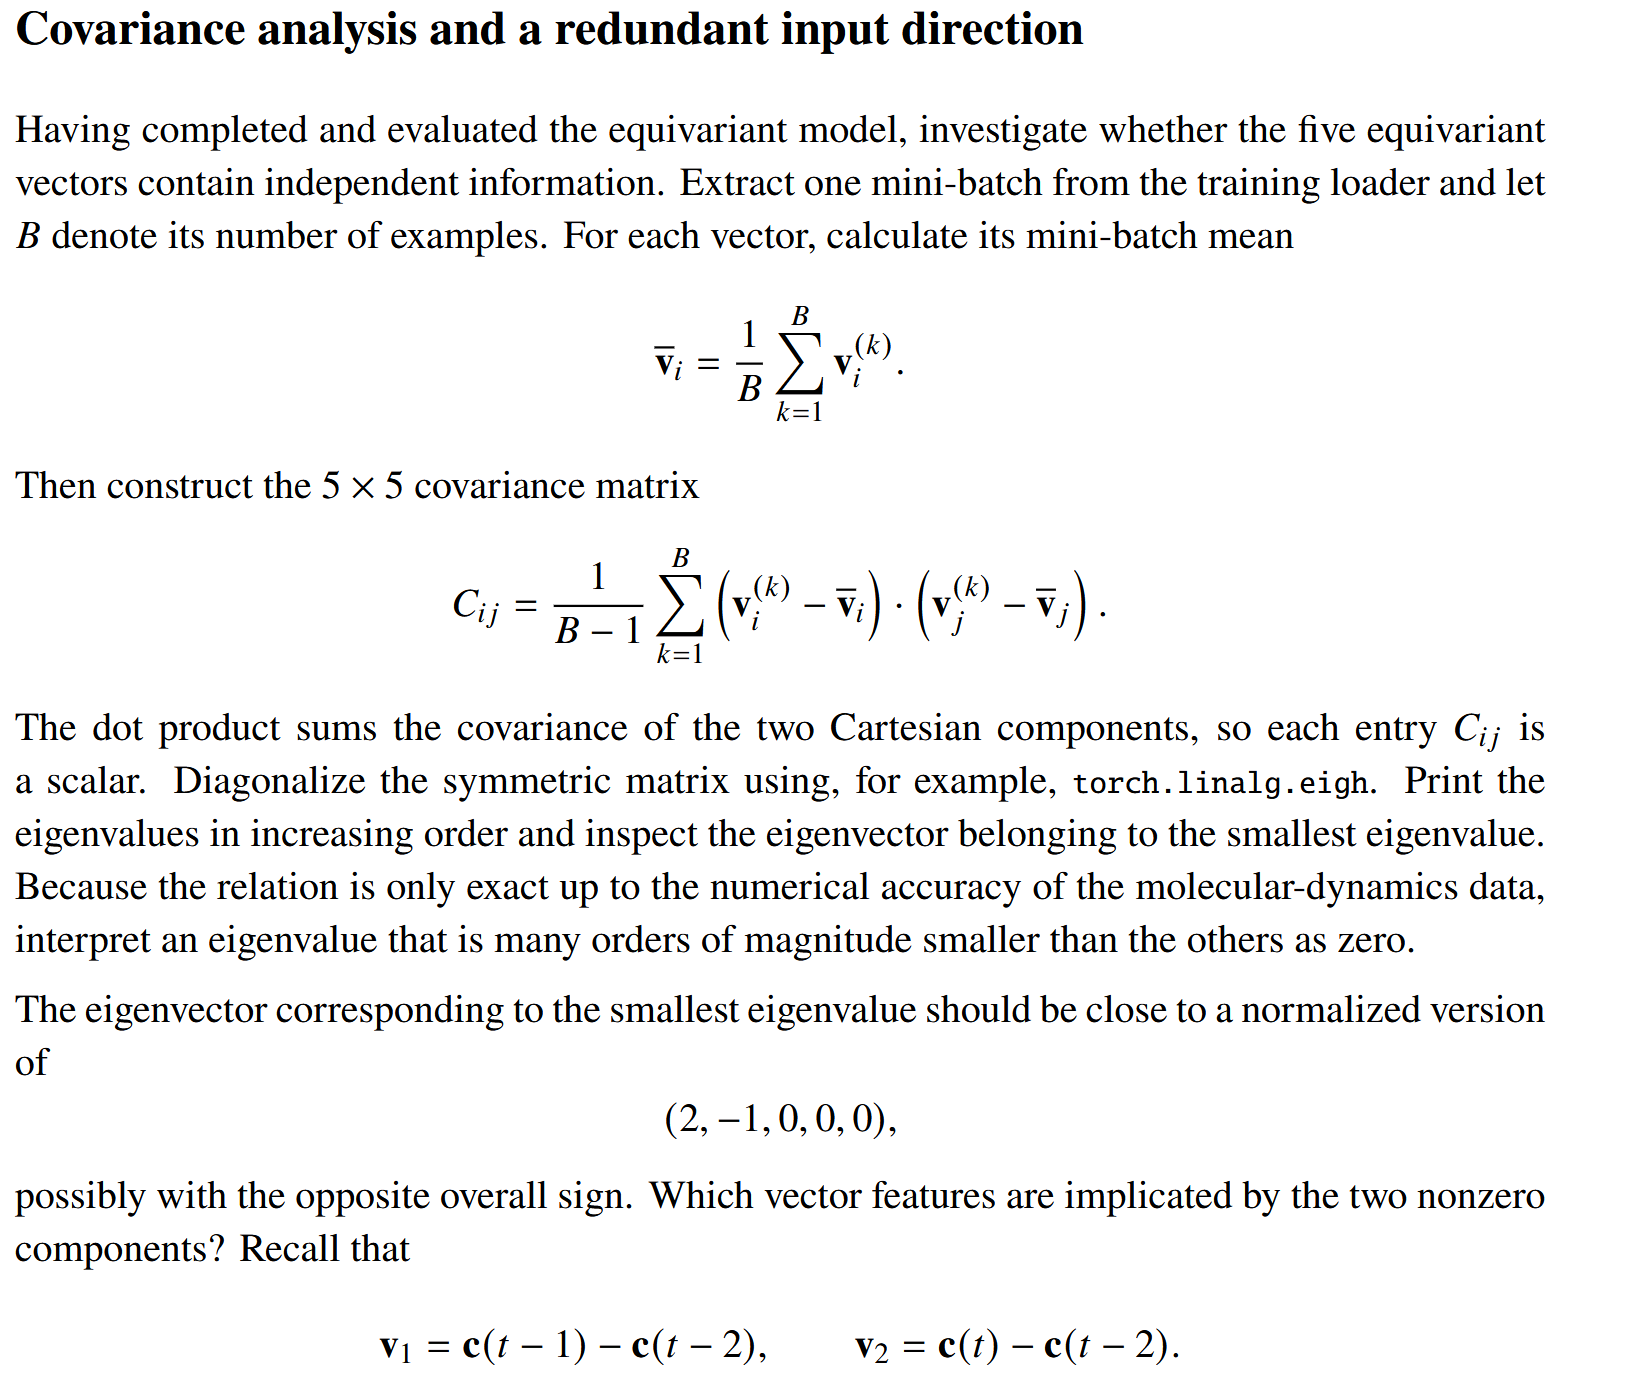
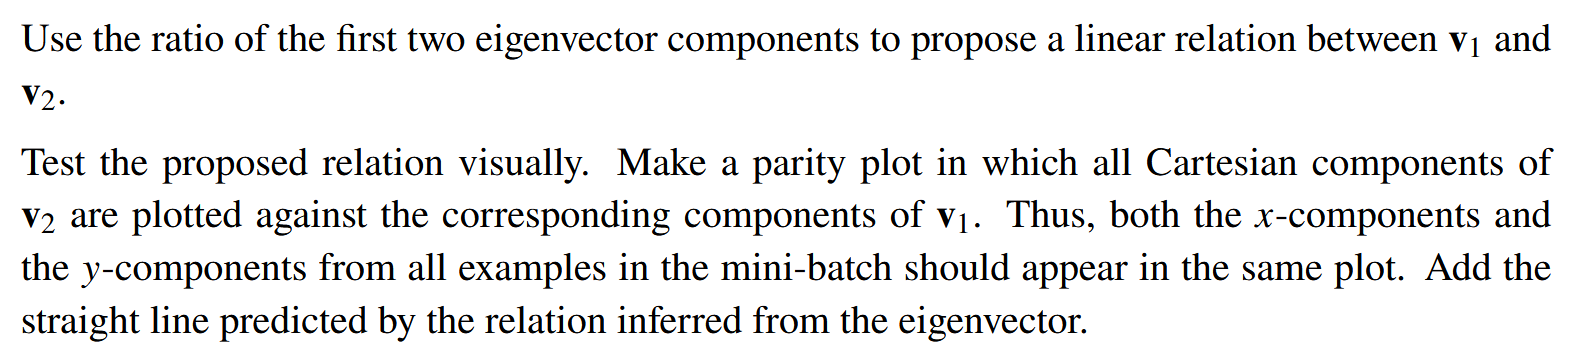
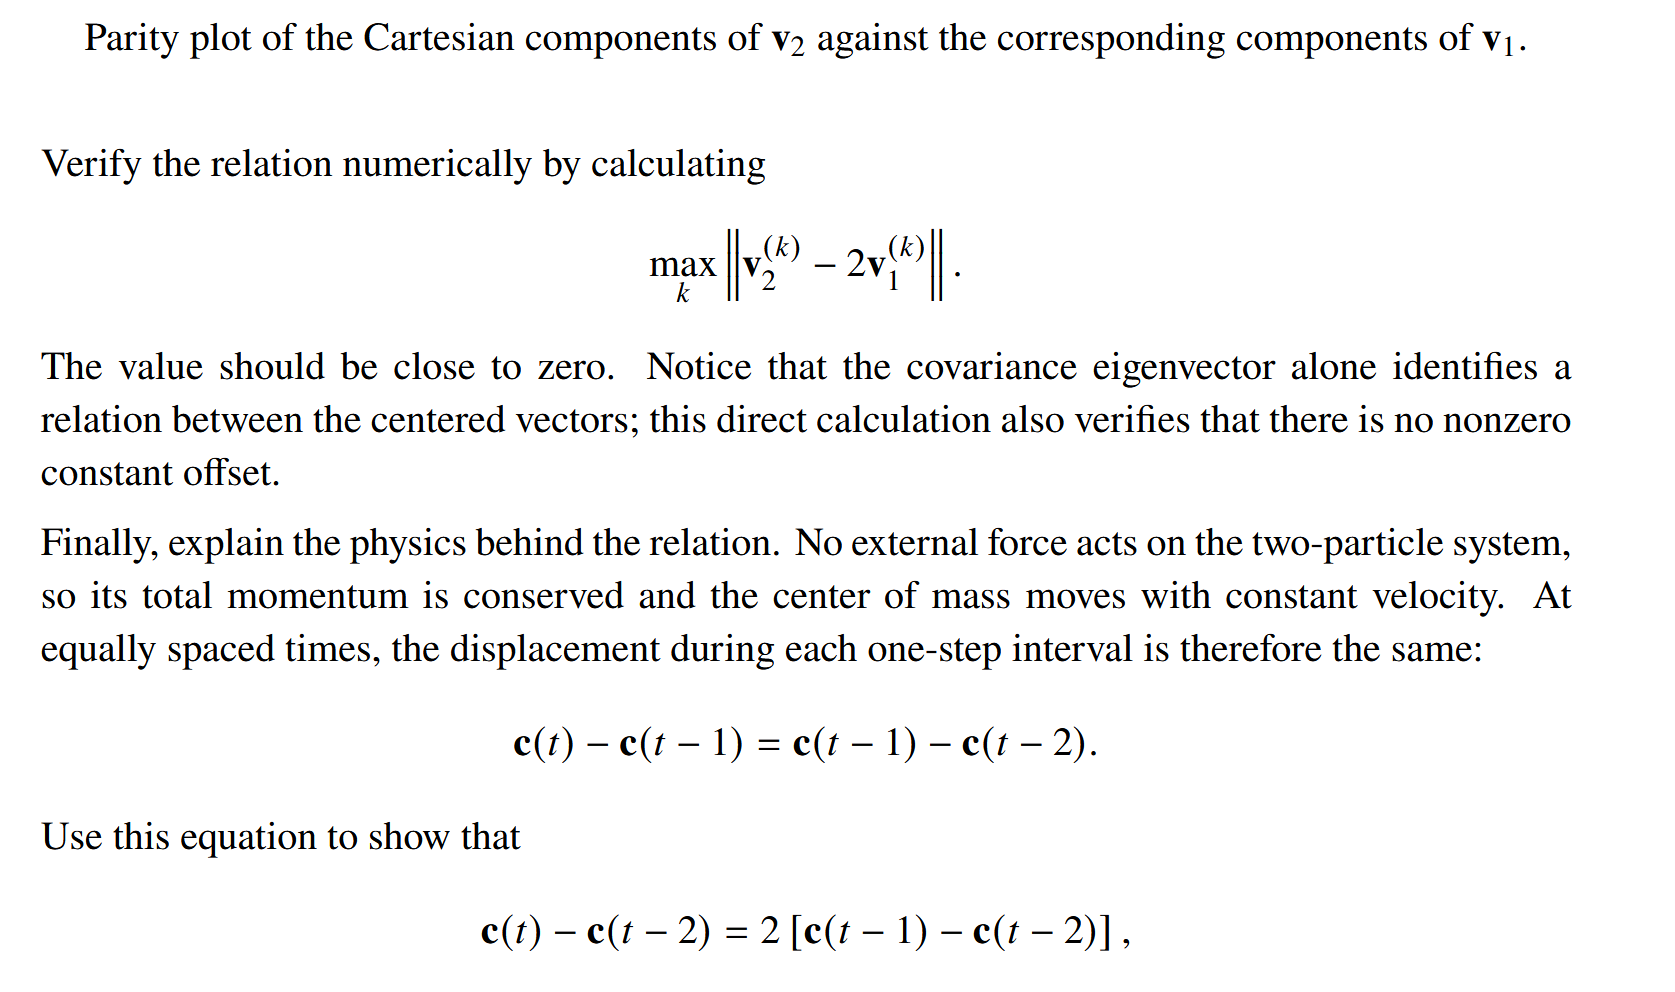

Eigenvalues:
-2.67e-07
1.64e-03
1.68e-01
3.04e-01
9.54e+00

Eigenvector for smallest eigenvalue:
[-8.9442682e-01  4.4721472e-01 -3.7548711e-05  7.3305884e-05
 -3.6800786e-05]


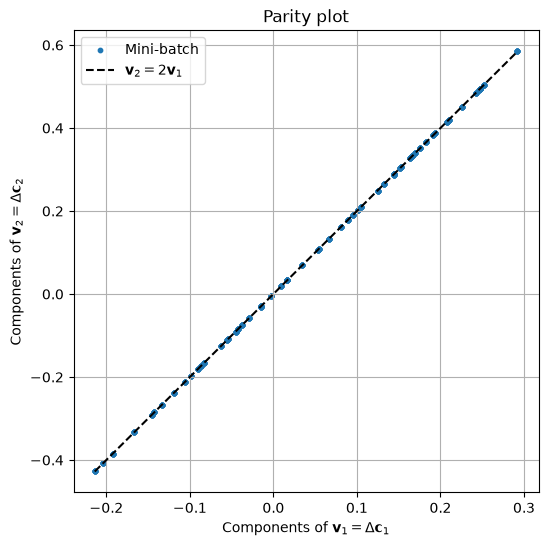

Max deviation for v2 = 2*v1: 2.3842e-07


In [39]:
for batch_x, _ in train_loader:
    break
    
r = batch_x.view(-1, 3, 2, 2)
c = 0.5 * (r[:, :, 0, :] + r[:, :, 1, :])
q = r[:, :, 0, :] - r[:, :, 1, :]

v1 = c[:, 1, :] - c[:, 0, :]
v2 = c[:, 2, :] - c[:, 0, :]
v3 = q[:, 0, :]
v4 = q[:, 1, :]
v5 = q[:, 2, :]

vectors = torch.stack((v1, v2, v3, v4, v5), dim=1) 
B = vectors.shape[0]

v_mean = torch.mean(vectors, dim=0)

C = torch.zeros((5, 5))
for i in range(5):
    for j in range(5):
        dot_products = torch.sum((vectors[:, i, :] - v_mean[i]) * (vectors[:, j, :] - v_mean[j]), dim=1)
        C[i, j] = torch.sum(dot_products) / (B - 1)

eigenvalues, eigenvectors = torch.linalg.eigh(C)

print("Eigenvalues:")
for val in eigenvalues:
    print(f"{val.item():.2e}")

print("\nEigenvector for smallest eigenvalue:")
print(eigenvectors[:, 0].numpy())

plt.figure(figsize=(6, 6))
plt.scatter(v1.flatten().numpy(), v2.flatten().numpy(), label='Mini-batch', s=10)
x_vals = torch.linspace(torch.min(v1), torch.max(v1), 100)
plt.plot(x_vals, 2 * x_vals, color='black', linestyle='--', label=r'$\mathbf{v}_2 = 2\mathbf{v}_1$')
plt.title('Parity plot')
plt.xlabel(r'Components of $\mathbf{v}_1 = \Delta\mathbf{c}_1$')
plt.ylabel(r'Components of $\mathbf{v}_2 = \Delta\mathbf{c}_2$')
plt.grid(True)
plt.legend()
plt.show()

max_deviation = torch.max(torch.abs(v2 - 2 * v1))
print(f"Max deviation for v2 = 2*v1: {max_deviation.item():.4e}")


### Physics of the Redundant Vector

The covariance analysis reveals an eigenvalue many orders of magnitude smaller than the rest, which corresponds to the eigenvector roughly proportional to $(2, -1, 0, 0, 0)$. This implicates a direct linear relationship between $v_1$ and $v_2$, which are the relative displacement vectors of the system's center of mass over sequential time steps.

Because no external force acts on the two-particle system, total momentum is conserved, and the center of mass moves with a constant velocity. Over equally spaced time steps, this physical law dictates that $c(t) - c(t-1) = c(t-1) - c(t-2)$.
Using simple algebra on the definition of $v_2$:
$v_2 = c(t) - c(t-2)$
$v_2 = [c(t) - c(t-1)] + [c(t-1) - c(t-2)]$
Substituting the constant velocity relation:
$v_2 = 2[c(t-1) - c(t-2)]$
$v_2 = 2v_1$.

This identity perfectly matches the eigenvector $(2, -1, 0, 0, 0)$, because the linear equation $2v_1 - 1v_2 + 0v_3 + 0v_4 + 0v_5 = 0$ corresponds exactly to $v_2 = 2v_1$.

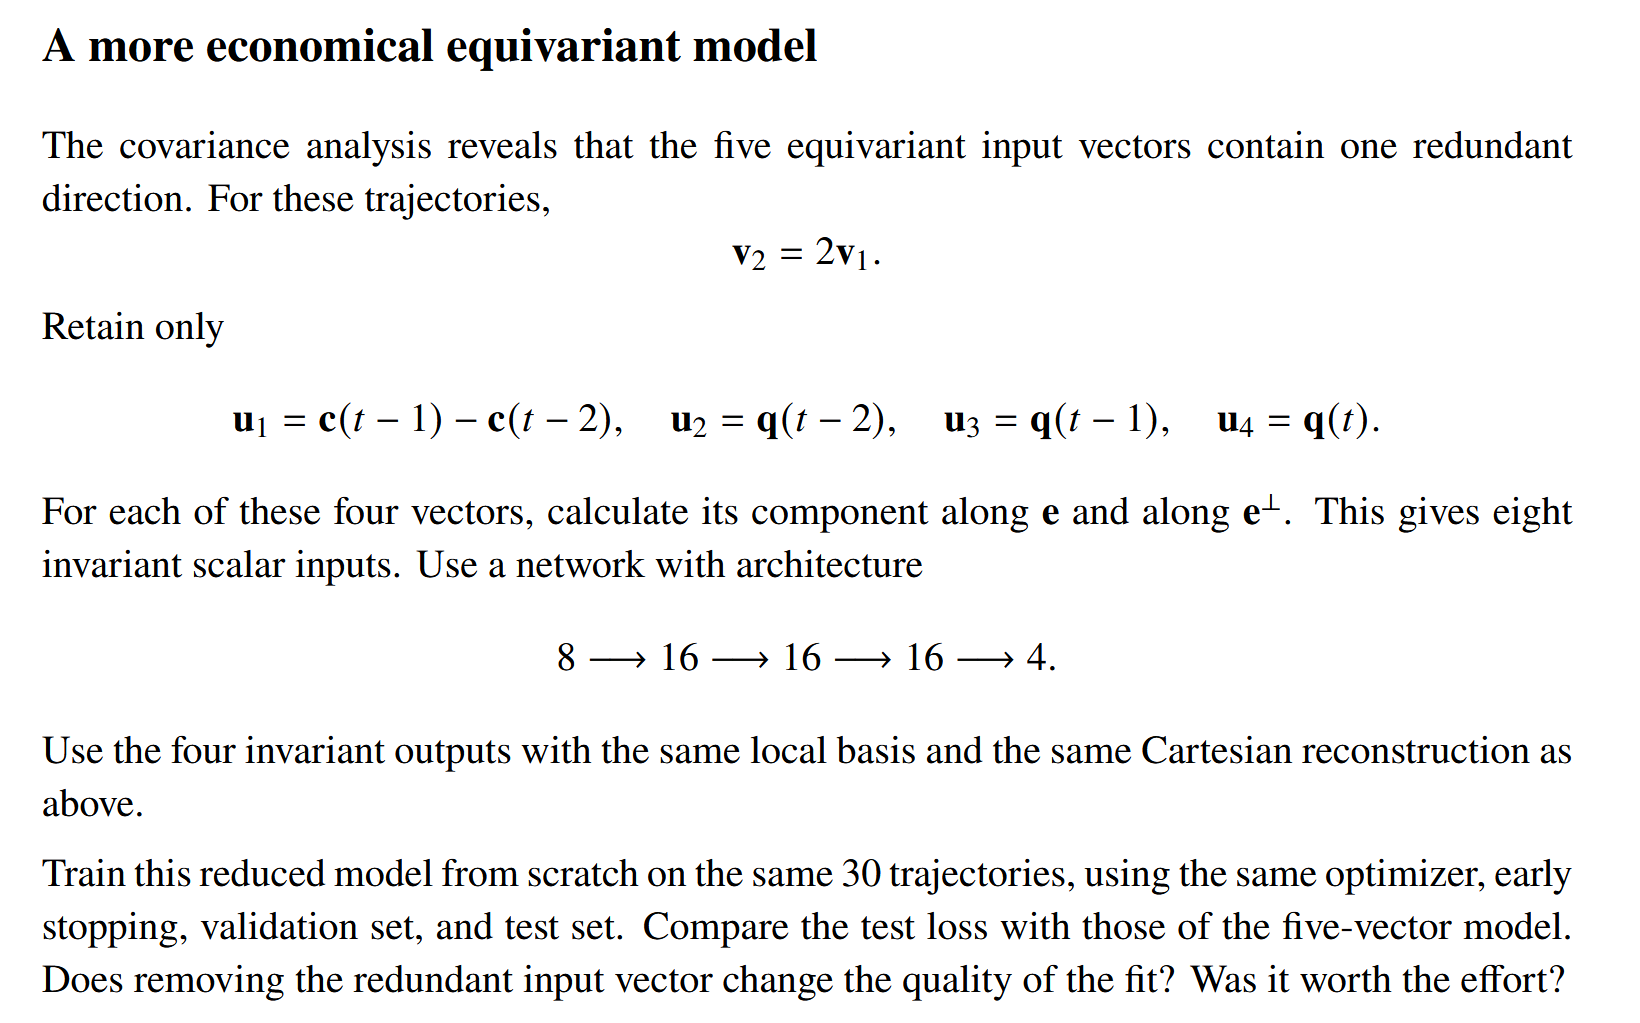

Final Test Loss: 0.000060


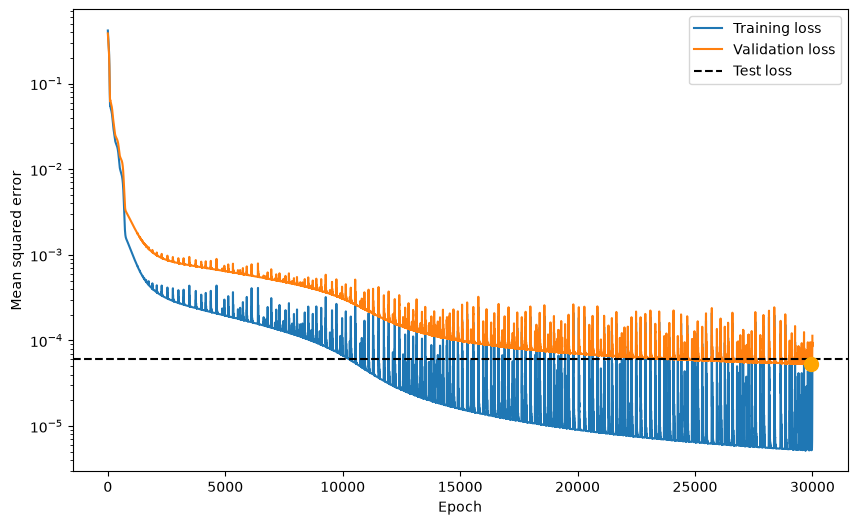

Original 10-feature Test Loss: 1.400934e-04
Reduced 8-feature Test Loss: 6.033278e-05


In [41]:
class EconomicalEquivariantModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(8, 16),
            nn.SiLU(),
            nn.Linear(16, 16),
            nn.SiLU(),
            nn.Linear(16, 16),
            nn.SiLU(),
            nn.Linear(16, 4)
        )

    def forward(self, x):
        r = x.view(-1, 3, 2, 2)
        
        c = 0.5 * (r[:, :, 0, :] + r[:, :, 1, :])
        q = r[:, :, 0, :] - r[:, :, 1, :]
        
        u1 = c[:, 1, :] - c[:, 0, :]
        u2 = q[:, 0, :]
        u3 = q[:, 1, :]
        u4 = q[:, 2, :]
        
        vectors = torch.stack((u1, u2, u3, u4), dim=1)
        
        rho1 = r[:, 2, 0, :] - c[:, 2, :]
        e = rho1 / torch.linalg.vector_norm(rho1, dim=1, keepdim=True)
        e_perp = torch.stack((-e[:, 1], e[:, 0]), dim=1)
        
        parallel = torch.sum(vectors * e[:, None, :], dim=2)
        perpendicular = torch.sum(vectors * e_perp[:, None, :], dim=2)
        
        invariants = torch.cat((parallel, perpendicular), dim=1)
        
        out = self.net(invariants)
        
        a11, a12, a21, a22 = out[:, 0:1], out[:, 1:2], out[:, 2:3], out[:, 3:4]
        
        c_t = c[:, 2, :]
        
        r1_hat = c_t + a11 * e + a12 * e_perp
        r2_hat = c_t + a21 * e + a22 * e_perp
        
        return torch.cat((r1_hat, r2_hat), dim=1)

eco_model = EconomicalEquivariantModel()
trained_eco_model, eco_history = fit_model(
    model=eco_model,
    train_loader=train_loader,
    criterion=nn.MSELoss(),
    optimizer_class=torch.optim.Adam,
    lr=1e-3,
    val_loader=val_loader,
    test_loader=test_loader,
    epochs=30000, 
    patience=1000
)

plt.figure(figsize=(10, 6))
plt.plot(eco_history['train_loss'], label='Training loss')
plt.plot(eco_history['val_loss'], label='Validation loss')

best_val_loss = min(eco_history['val_loss'])
best_epoch_idx = eco_history['val_loss'].index(best_val_loss)

plt.axhline(y=eco_history['test_loss'], color='k', linestyle='--', label='Test loss')
plt.scatter([best_epoch_idx], [best_val_loss], color='orange', s=100, zorder=5)

plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Mean squared error')
plt.legend()
plt.show()

print(f"Original 10-feature Test Loss: {history['test_loss']:.6e}")
print(f"Reduced 8-feature Test Loss: {eco_history['test_loss']:.6e}")
